In [27]:
!pip install xgboost lightgbm catboost category_encoders

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [29]:
df=pd.read_csv('House_Rent_Dataset.csv')
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


| Column                | معناه بالعربي                                                 | مثال من البيانات                                        |
| --------------------- | ------------------------------------------------------------- | ------------------------------------------------------- |
| **Posted On**         | تاريخ نشر إعلان الشقة                                         | `5/18/2022` → 18 مايو 2022                              |
| **BHK**               | عدد غرف النوم + المعيشة، وغالبًا يشير لعدد غرف النوم في الشقة | `2` → شقة 2 BHK                                         |
| **Rent**              | قيمة الإيجار                                                  | `10000` → الإيجار 10,000                                |
| **Size**              | مساحة الشقة                                                   | `1100` → المساحة 1100 قدم مربع غالبًا                   |
| **Floor**             | الدور الذي توجد فيه الشقة + عدد أدوار المبنى                  | `Ground out of 2` → الدور الأرضي من مبنى مكوّن من دورين |
| **Area Type**         | نوع المساحة المحسوبة                                          | `Super Area` أو `Carpet Area`                           |
| **Area Locality**     | المنطقة أو الحي الموجود فيه العقار                            | `Bandel`                                                |
| **City**              | المدينة التي توجد فيها الشقة                                  | `Kolkata` → كولكاتا                                     |
| **Furnishing Status** | حالة تأثيث الشقة                                              | `Unfurnished` → غير مفروشة                              |
| **Tenant Preferred**  | نوع المستأجر الذي يفضله صاحب العقار                           | `Bachelors/Family` → أفراد عزاب أو عائلات               |
| **Bathroom**          | عدد الحمامات                                                  | `2.0` → حمامان                                          |
| **Point of Contact**  | الشخص المسؤول عن التواصل بخصوص الإعلان                        | `Contact Owner` → التواصل مع المالك                     |


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [31]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [32]:
df.shape

(4746, 12)

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
df.drop(columns=['Posted On','Point of Contact'],axis=1,inplace=True)

In [35]:
df.isna().sum()

,0
BHK,0
Rent,5
Size,8
Floor,0
Area Type,7
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,4


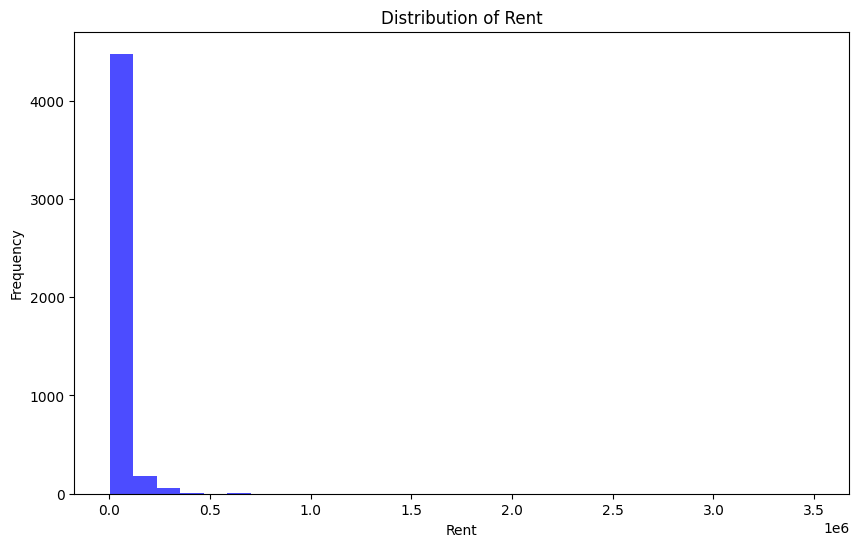

In [36]:
plt.figure(figsize=(10,6))
plt.hist(df['Rent'], bins=30, color='blue', alpha=0.7)
plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.ylabel('Frequency')
plt.show()

In [37]:
df['Rent'].skew()

np.float64(21.402053848072253)

In [38]:
df[df['Rent'].isna()].head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom
14,3,NaN,900.0,Ground out of 2,Carpet Area,Paschim Barisha,Kolkata,Unfurnished,Bachelors,NaN
26,1,NaN,355.0,1 out of 1,Carpet Area,Dum Dum,Kolkata,Semi-Furnished,Bachelors/Family,1.0
40,2,NaN,NaN,Ground out of 1,Carpet Area,Birati,Kolkata,Semi-Furnished,Bachelors/Family,1.0
55,1,NaN,NaN,Ground out of 2,Carpet Area,Behala,Kolkata,Unfurnished,Bachelors/Family,1.0
66,1,NaN,300.0,Ground out of 2,Carpet Area,Kasba,Kolkata,Unfurnished,Bachelors/Family,1.0


In [39]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df['Rent'] = imputer.fit_transform(df[['Rent']])

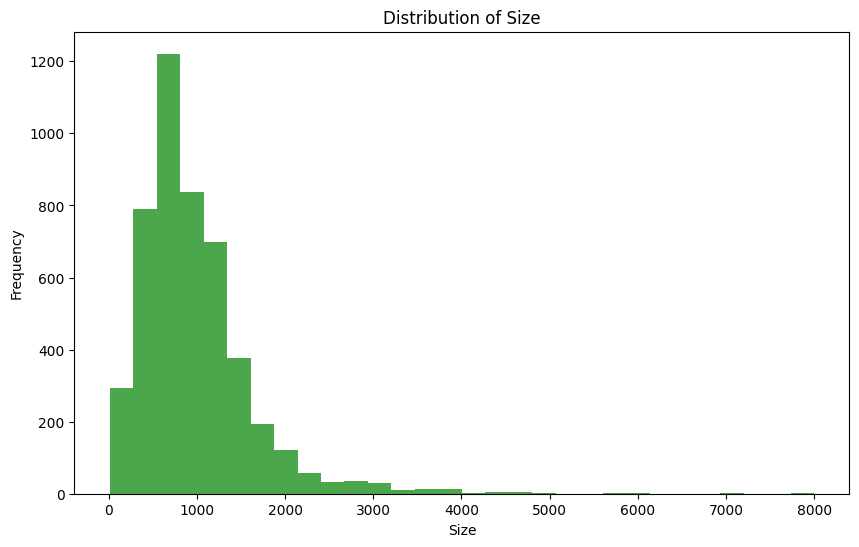

In [40]:
plt.figure(figsize=(10,6))
plt.hist(df['Size'], bins=30, color='green', alpha=0.7)
plt.title('Distribution of Size')
plt.xlabel('Size')
plt.ylabel('Frequency')
plt.show()

In [41]:
df['Size'].skew()

np.float64(2.2981542396330705)

In [42]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df['Size'] = imputer.fit_transform(df[['Size']])

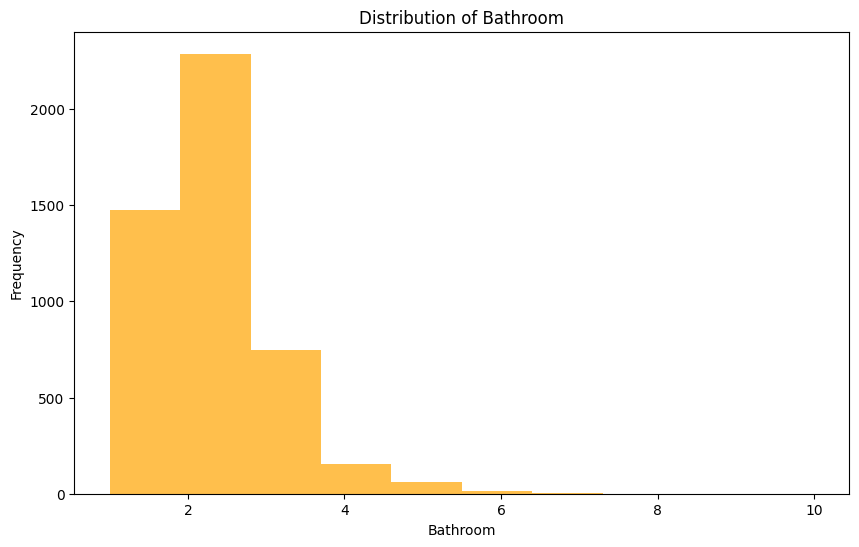

In [43]:
plt.figure(figsize=(10,6))
plt.hist(df['Bathroom'], bins=10, color='orange', alpha=0.7)
plt.title('Distribution of Bathroom')
plt.xlabel('Bathroom')
plt.ylabel('Frequency')
plt.show()

In [44]:
df['Bathroom'].skew()

np.float64(1.2725152257787251)

In [45]:
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df['Bathroom'] = imputer.fit_transform(df[['Bathroom']]).ravel()

In [46]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df[['Area Type']] = imputer.fit_transform(df[['Area Type']])

In [47]:
df.isna().sum()

,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,0


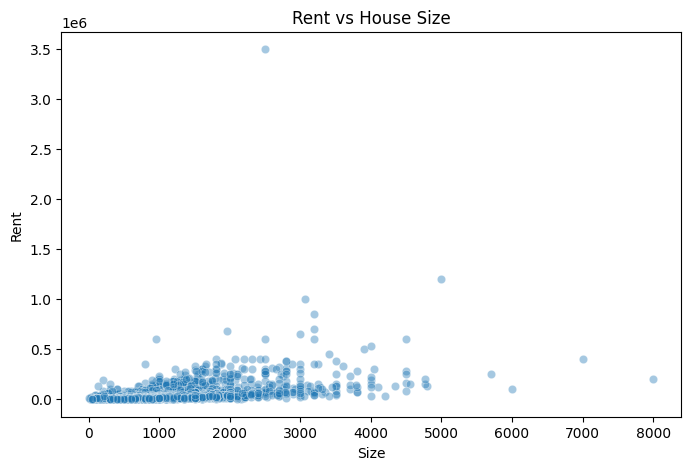

In [48]:
import seaborn as sns
plt.figure(figsize=(8,5))
sns.scatterplot(x="Size", y="Rent", data=df, alpha=0.4)
plt.title("Rent vs House Size")
plt.xlabel("Size")
plt.ylabel("Rent")
plt.show()

In [49]:
df.select_dtypes(include=['object']).nunique()


,0
Floor,480
Area Type,3
Area Locality,2235
City,6
Furnishing Status,3
Tenant Preferred,3


In [50]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in ['Area Type',  'Furnishing Status', 'Tenant Preferred']:
    df[col] = le.fit_transform(df[col])

In [51]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    handle_unknown='ignore')

ohe_encoded = ohe.fit_transform(df[['City']]).toarray()
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out(['City']),
    index=df.index
)

df = pd.concat([df, ohe_df], axis=1)
df.drop("City",axis =1 ,inplace =True)

In [52]:
import  category_encoders as ce

In [53]:
import sys
print(sys.executable)

/usr/bin/python3


In [54]:
import sys
!{sys.executable} -m pip install category_encoders

In [55]:
# target_enc = ce.TargetEncoder(
#     cols=['job_title', 'employee_residence'],
#     smoothing=5
# )

# df[['job_title_new', 'employee_residence']] = target_enc.fit_transform(
#     df[['job_title', 'employee_residence']], df['salary']
# )

In [56]:
df.select_dtypes(include=['number']).nunique()

,0
BHK,6
Rent,243
Size,615
Area Type,3
Furnishing Status,3
Tenant Preferred,3
Bathroom,8
City_Bangalore,2
City_Chennai,2
City_Delhi,2


In [57]:
cols = ['BHK', 'Rent', 'Size', 'Bathroom']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outliers')
    print(f'Lower = {lower}')
    print(f'Upper = {upper}')
    print('--------------------')

BHK: 27 outliers
Lower = 0.5
Upper = 4.5
--------------------
Rent: 520 outliers
Lower = -24500.0
Upper = 67500.0
--------------------
Size: 203 outliers
Lower = -425.0
Upper = 2175.0
--------------------
Bathroom: 232 outliers
Lower = -0.5
Upper = 3.5
--------------------


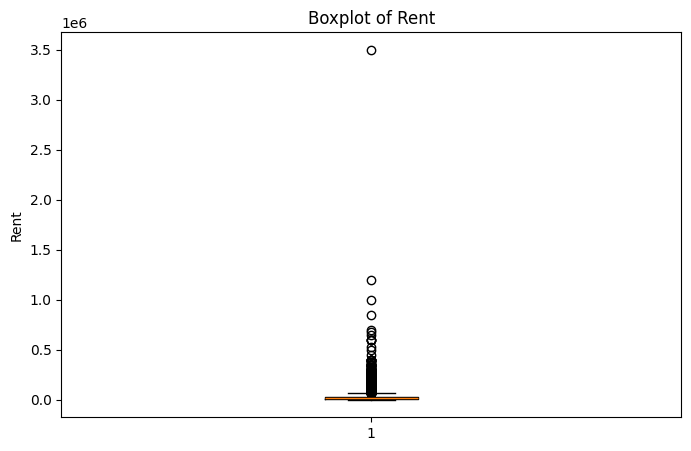

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.boxplot(df['Rent'].dropna())
plt.ylabel('Rent')
plt.title('Boxplot of Rent')
plt.show()

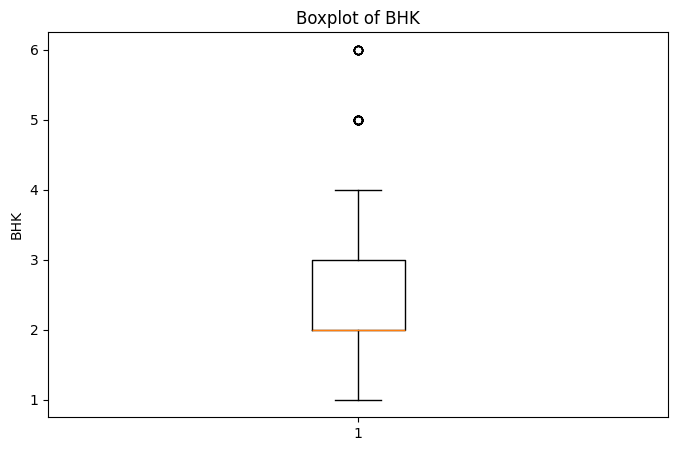

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.boxplot(df['BHK'].dropna())
plt.ylabel('BHK')
plt.title('Boxplot of BHK')
plt.show()

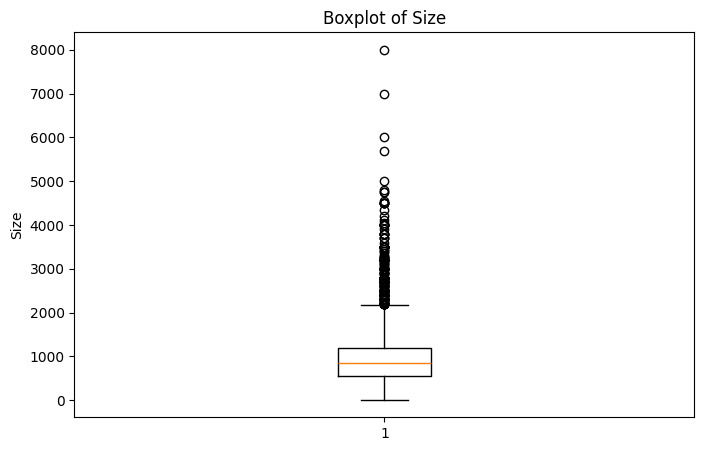

In [60]:

plt.figure(figsize=(8, 5))
plt.boxplot(df['Size'].dropna())
plt.ylabel('Size')
plt.title('Boxplot of Size')
plt.show()

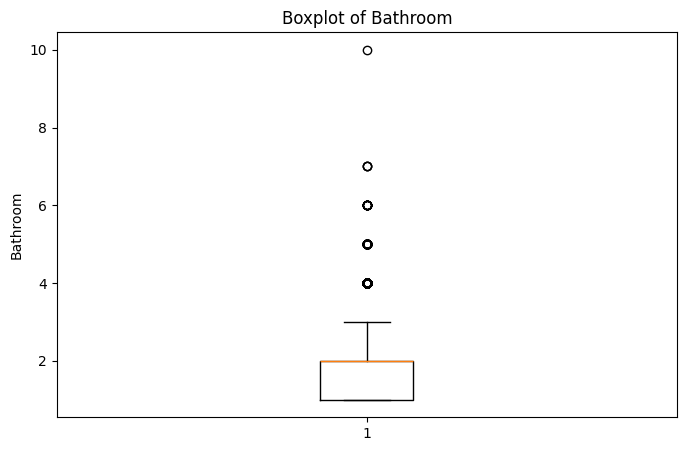

In [61]:
plt.figure(figsize=(8, 5))
plt.boxplot(df['Bathroom'].dropna())
plt.ylabel('Bathroom')
plt.title('Boxplot of Bathroom')
plt.show()

In [62]:
rent_outliers = df[df['Rent'] > 67500]

rent_outliers[['Rent', 'BHK', 'Size', 'Bathroom',  'Area Locality']].sort_values('Rent', ascending=False)

,Rent,BHK,Size,Bathroom,Area Locality
1837,3500000.0,3,2500.0,3.0,Marathahalli
1001,1200000.0,4,5000.0,4.0,Juhu
827,1000000.0,4,3064.0,4.0,"Raheja Artesia, Worli"
1329,850000.0,4,3200.0,4.0,Breach Candy
1459,700000.0,4,3200.0,4.0,"Lady Ratan Tower, Worli"
...,...,...,...,...,...
558,68000.0,2,610.0,2.0,shivsagar
1012,68000.0,3,1260.0,3.0,"Alta Monte, Pathanwadi"
967,68000.0,2,805.0,3.0,"Auris Serenity, Kanch Pada"
2843,68000.0,3,1450.0,3.0,Lajpat Nagar 3


In [63]:
size_outliers = df[df['Size'] > 2175]

size_outliers[['Size', 'Rent', 'BHK', 'Bathroom',  'Area Locality']].sort_values('Size', ascending=False)

,Size,Rent,BHK,Bathroom,Area Locality
4185,8000.0,200000.0,1,10.0,"Beeramguda, Ramachandra Puram, NH 9"
4457,7000.0,400000.0,4,6.0,Jubilee Hills
3622,6000.0,100000.0,5,4.0,Navalur
2048,5700.0,250000.0,4,4.0,whitefield
1001,5000.0,1200000.0,4,4.0,Juhu
...,...,...,...,...,...
3230,2200.0,65000.0,3,3.0,Alwarpet
2623,2200.0,140000.0,3,3.0,Defence Colony
2610,2200.0,21000.0,3,2.0,Vivek Vihar
4088,2200.0,27000.0,3,3.0,Toli Chowki


In [64]:
bathroom_outliers = df[df['Bathroom'] > 3.5]

bathroom_outliers[['Bathroom', 'BHK', 'Size', 'Rent',  'Area Locality']] \
    .sort_values('Bathroom', ascending=False)

,Bathroom,BHK,Size,Rent,Area Locality
4185,10.0,1,8000.0,200000.0,"Beeramguda, Ramachandra Puram, NH 9"
4518,7.0,6,3400.0,35000.0,Rampally
2846,7.0,4,4000.0,150000.0,West End
4350,7.0,6,2800.0,60000.0,"Boduppal, NH 2 2"
1160,6.0,4,2308.0,300000.0,"Windsor Grande Residences, Andheri West"
...,...,...,...,...,...
4477,4.0,3,1700.0,24000.0,"Manikonda, Outer Ring Road"
4425,4.0,4,3455.0,120000.0,Madhapur
4625,4.0,3,1800.0,20000.0,Manigunda
4635,4.0,4,2300.0,45000.0,Punjagutta X Roads


In [65]:

x=df.drop(['Rent'], axis=1)
y = np.log1p(df["Rent"])



In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x,y,
                                   test_size= 0.20, random_state=100, stratify=None)

print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (3796, 14)  y_train =  (3796,)
X_test  =  (950, 14)  y_test  =  (950,)


In [67]:
X_train.head()

,BHK,Size,Floor,Area Type,Area Locality,Furnishing Status,Tenant Preferred,Bathroom,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai
4069,2,1000.0,2 out of 5,2,"Ashok Nagar, Himayath Nagar",1,1,2.0,0.0,0.0,0.0,1.0,0.0,0.0
2230,2,800.0,1 out of 4,2,Kengeri Hobli,2,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1666,2,600.0,1 out of 4,2,"Mallasandra, Jalahalli West",1,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0
3590,2,730.0,2 out of 2,1,Keelkattalai,1,2,2.0,0.0,1.0,0.0,0.0,0.0,0.0
4297,1,200.0,Ground out of 2,2,Moula Ali,2,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [68]:
target_enc = ce.TargetEncoder(
    cols=['Floor', 'Area Locality'],
    smoothing=5
)

X_train[['Floor_new', 'Area Locality_new']] = target_enc.fit_transform(
    X_train[['Floor', 'Area Locality']],
    y_train
)
X_test[['Floor_new', 'Area Locality_new']] = target_enc.transform(
    X_test[['Floor', 'Area Locality']]
)

In [69]:
X_train.head()

,BHK,Size,Floor,Area Type,Area Locality,Furnishing Status,Tenant Preferred,Bathroom,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Floor_new,Area Locality_new
4069,2,1000.0,2 out of 5,2,"Ashok Nagar, Himayath Nagar",1,1,2.0,0.0,0.0,0.0,1.0,0.0,0.0,9.818373,9.874955
2230,2,800.0,1 out of 4,2,Kengeri Hobli,2,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,9.692319,9.835945
1666,2,600.0,1 out of 4,2,"Mallasandra, Jalahalli West",1,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,9.692319,9.845063
3590,2,730.0,2 out of 2,1,Keelkattalai,1,2,2.0,0.0,1.0,0.0,0.0,0.0,0.0,9.470222,9.848949
4297,1,200.0,Ground out of 2,2,Moula Ali,2,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,9.322751,9.822542


In [70]:
X_train.drop(columns=['Floor', 'Area Locality'], inplace=True)
X_test.drop(columns=['Floor', 'Area Locality'], inplace=True)

In [71]:
X_train.describe()

,BHK,Size,Area Type,Furnishing Status,Tenant Preferred,Bathroom,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Floor_new,Area Locality_new
count,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000
mean,2.068230,961.564542,1.522129,1.239199,0.926765,1.953635,0.191517,0.186512,0.128030,0.183351,0.112223,0.198367,9.650395,9.872567
std,0.830786,635.640147,0.500630,0.681935,0.518344,0.886711,0.393547,0.389571,0.334167,0.387005,0.315683,0.398822,0.251069,0.140870
min,1.000000,10.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.284240,9.649740
25%,1.000000,550.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.410964,9.842141
50%,2.000000,850.000000,2.000000,1.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.693086,9.856599
75%,3.000000,1200.000000,2.000000,2.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.876877,9.880277
max,6.000000,8000.000000,2.000000,2.000000,2.000000,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,10.318279,11.427114


In [72]:
X_train.head()

,BHK,Size,Area Type,Furnishing Status,Tenant Preferred,Bathroom,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Floor_new,Area Locality_new
4069,2,1000.0,2,1,1,2.0,0.0,0.0,0.0,1.0,0.0,0.0,9.818373,9.874955
2230,2,800.0,2,2,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,9.692319,9.835945
1666,2,600.0,2,1,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,9.692319,9.845063
3590,2,730.0,1,1,2,2.0,0.0,1.0,0.0,0.0,0.0,0.0,9.470222,9.848949
4297,1,200.0,2,2,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,9.322751,9.822542


In [73]:
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0,1))
X_train[['Size','Floor_new','Area Locality_new']] = my_scaler.fit_transform(X_train[['Size','Floor_new','Area Locality_new']])
X_test[['Size','Floor_new','Area Locality_new']] = my_scaler.transform(X_test[['Size','Floor_new','Area Locality_new']])

In [74]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [75]:
y_pred=lr.predict(X_test)

In [76]:
lr.score(X_train, y_train)

0.8102633712585958

In [77]:
lr.score(X_test, y_test)

0.7986003746464916

In [78]:
from  sklearn.metrics import mean_absolute_error , mean_squared_error,root_mean_squared_error,r2_score
print("MAE : ",mean_absolute_error(y_test,y_pred))
print("MSE : ",mean_squared_error(y_test,y_pred))
print("RMSE : ",root_mean_squared_error(y_test,y_pred))
print("R2 : ",r2_score(y_test,y_pred))

MAE :  0.30944471660815903
MSE :  0.17717029075968685
RMSE :  0.42091601390263933
R2 :  0.7986003746464916


In [79]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [80]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

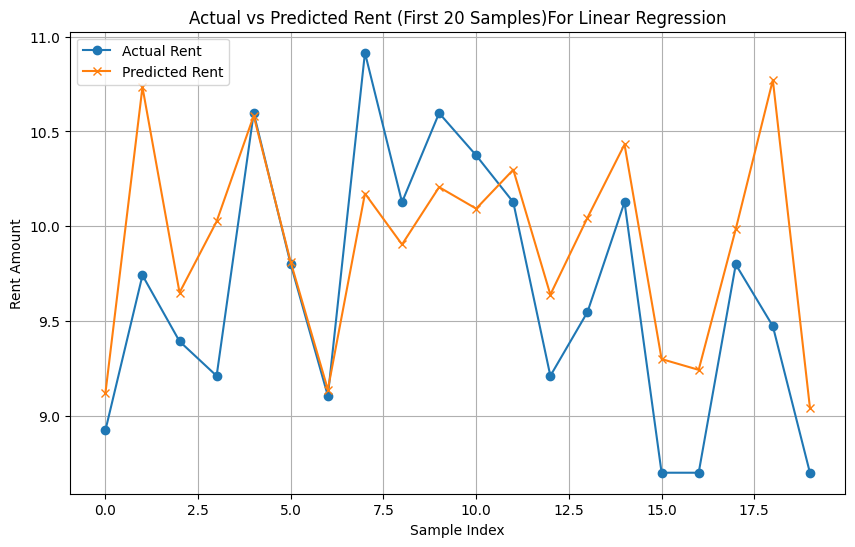

  7%|▋         | 1/15 [00:00<00:05,  2.51it/s]

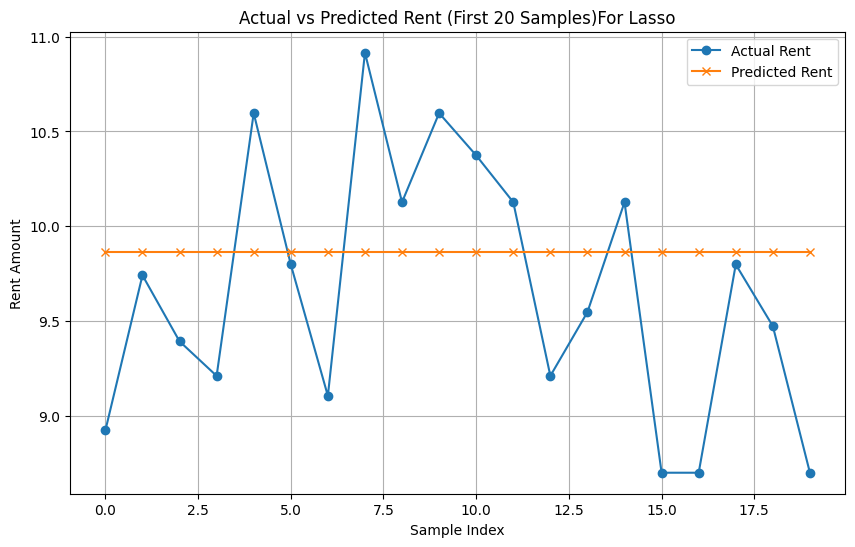

 13%|█▎        | 2/15 [00:00<00:04,  2.79it/s]

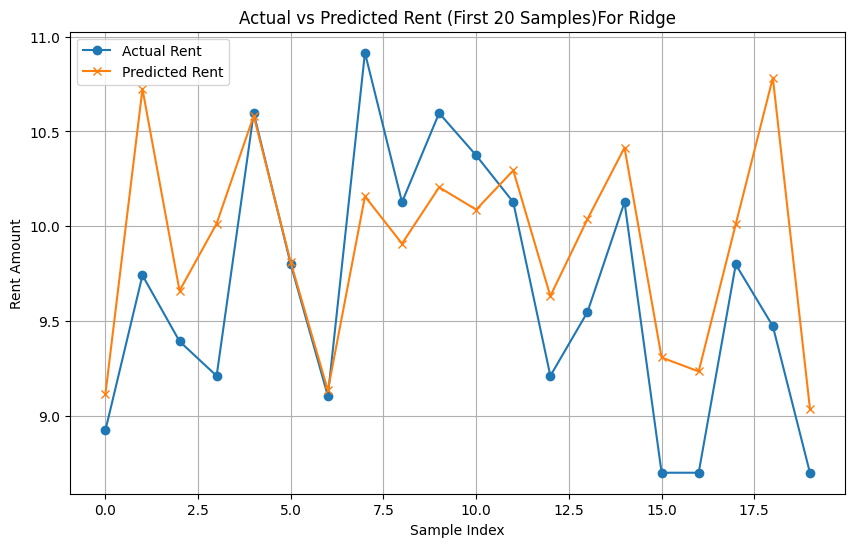

 20%|██        | 3/15 [00:01<00:04,  2.63it/s]

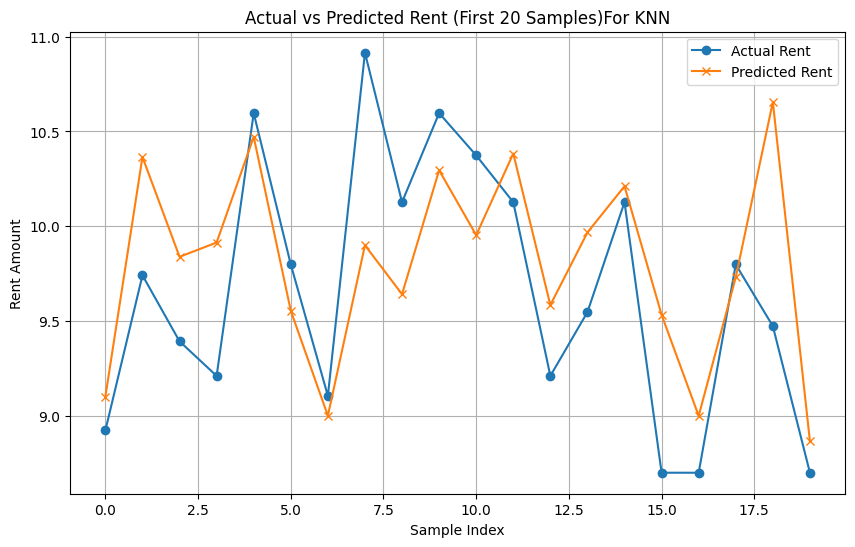

 27%|██▋       | 4/15 [00:02<00:06,  1.60it/s]

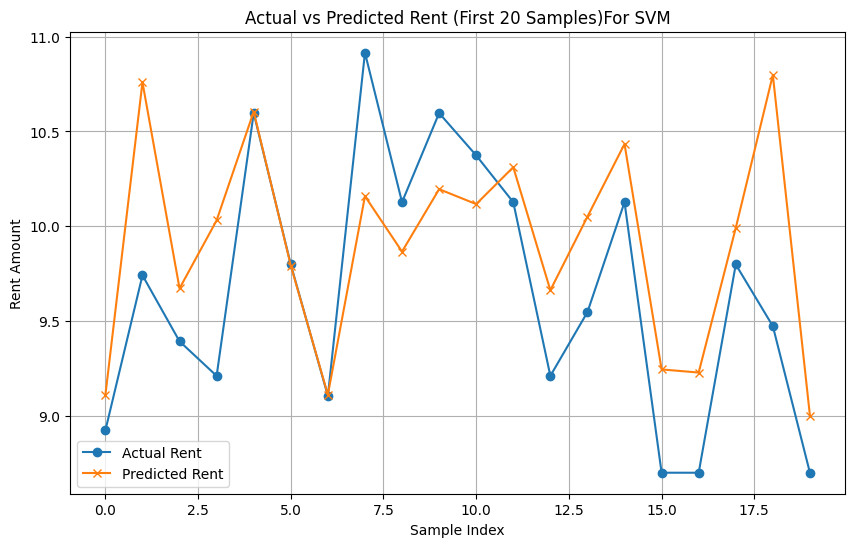

 33%|███▎      | 5/15 [00:26<01:30,  9.03s/it]

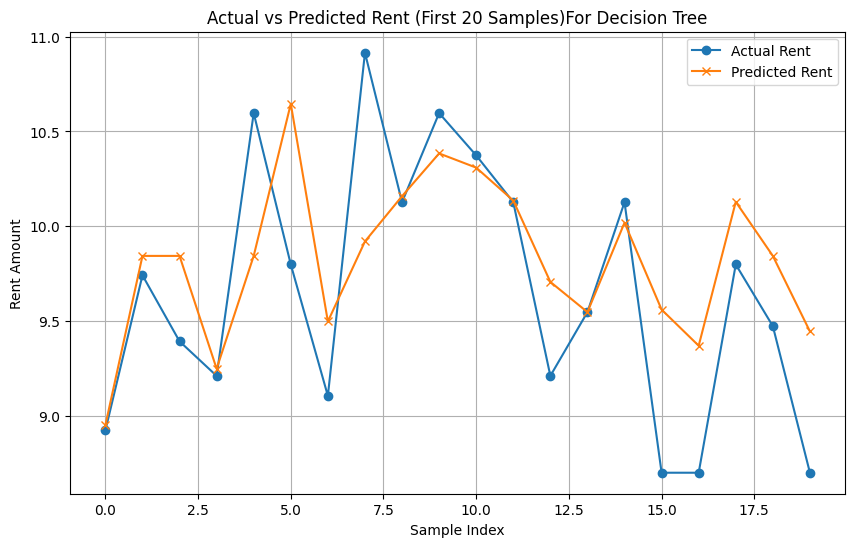

 40%|████      | 6/15 [00:26<00:54,  6.03s/it]

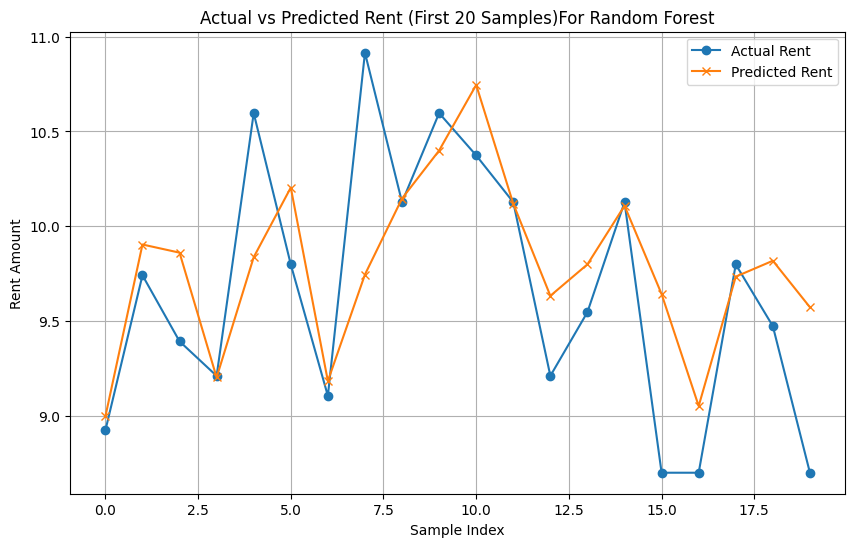

 47%|████▋     | 7/15 [00:27<00:34,  4.31s/it]

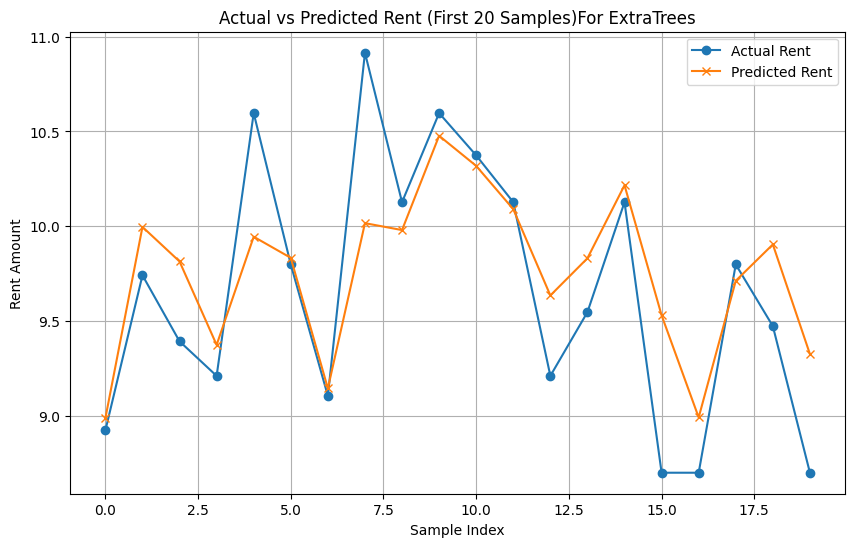

 53%|█████▎    | 8/15 [00:28<00:24,  3.43s/it]

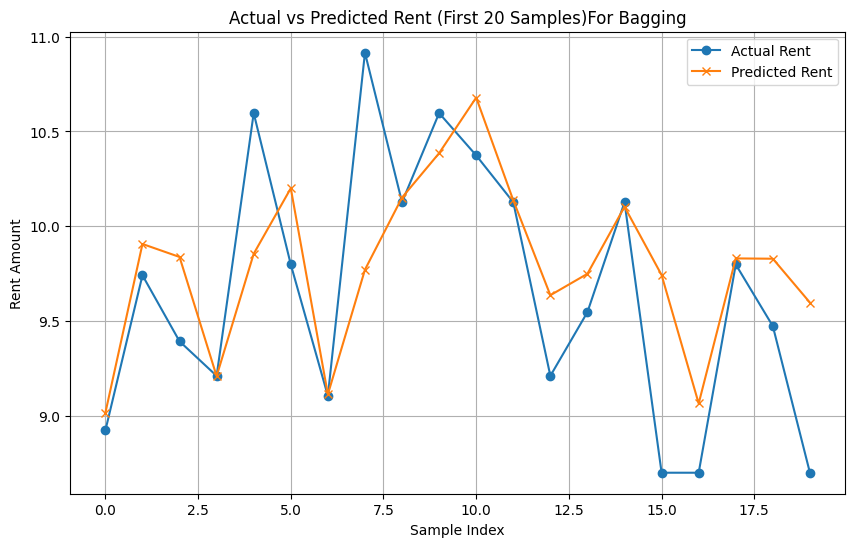

 60%|██████    | 9/15 [00:29<00:16,  2.72s/it]

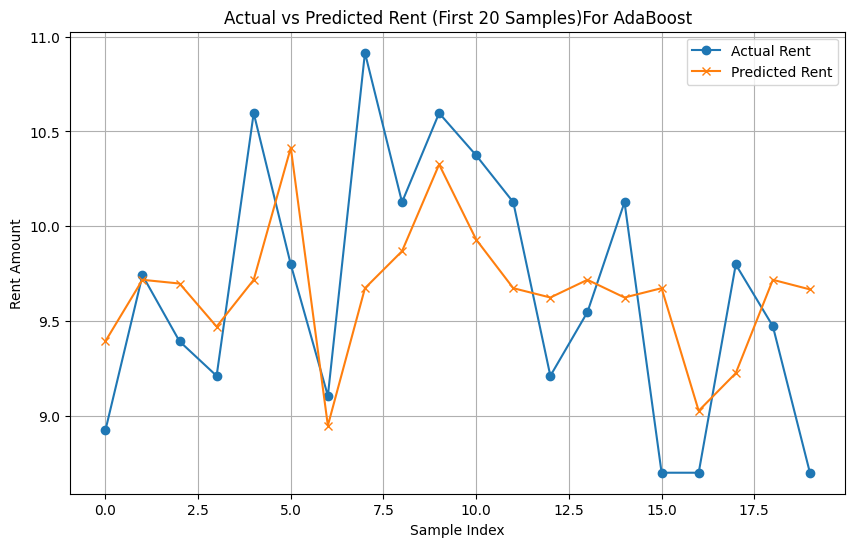

 67%|██████▋   | 10/15 [00:30<00:10,  2.02s/it]

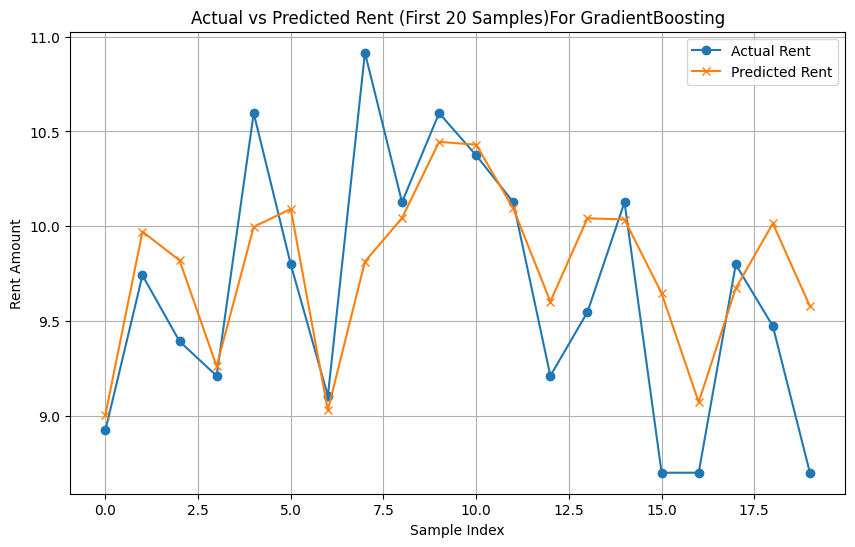

 73%|███████▎  | 11/15 [00:31<00:06,  1.69s/it]

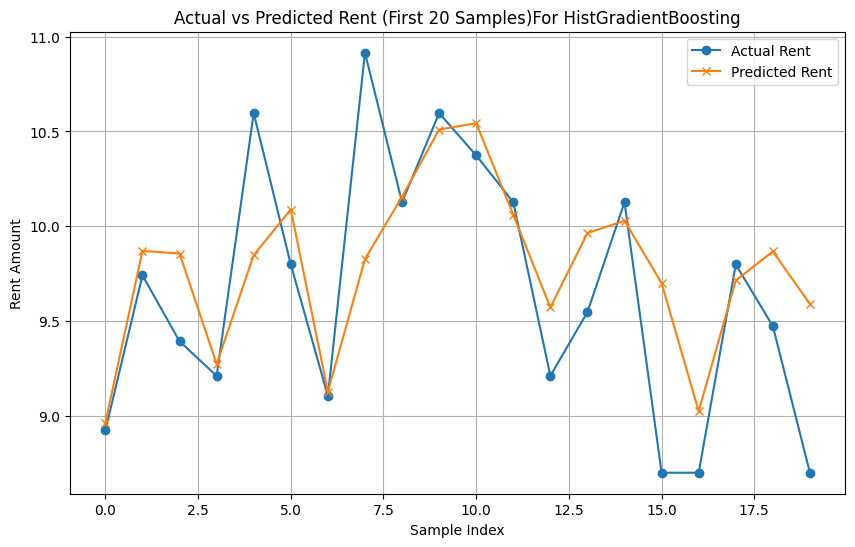

 80%|████████  | 12/15 [00:31<00:04,  1.42s/it]

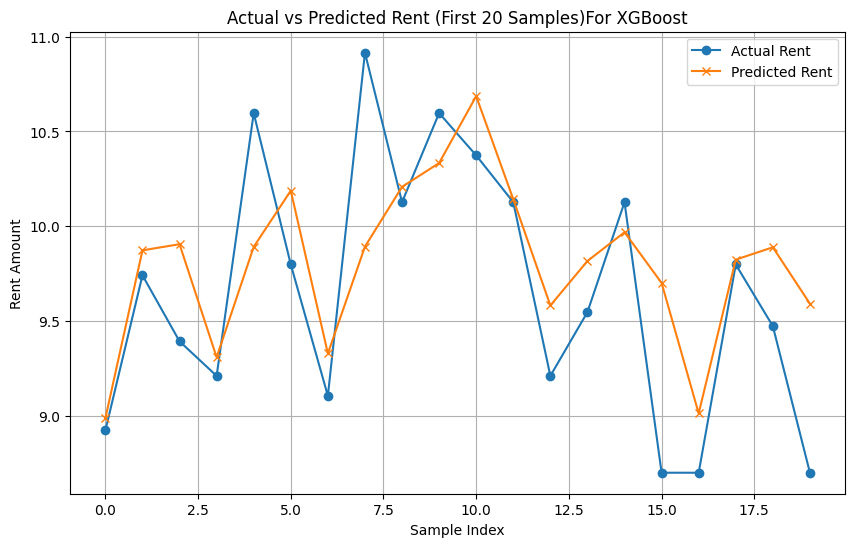

 87%|████████▋ | 13/15 [00:32<00:02,  1.11s/it]

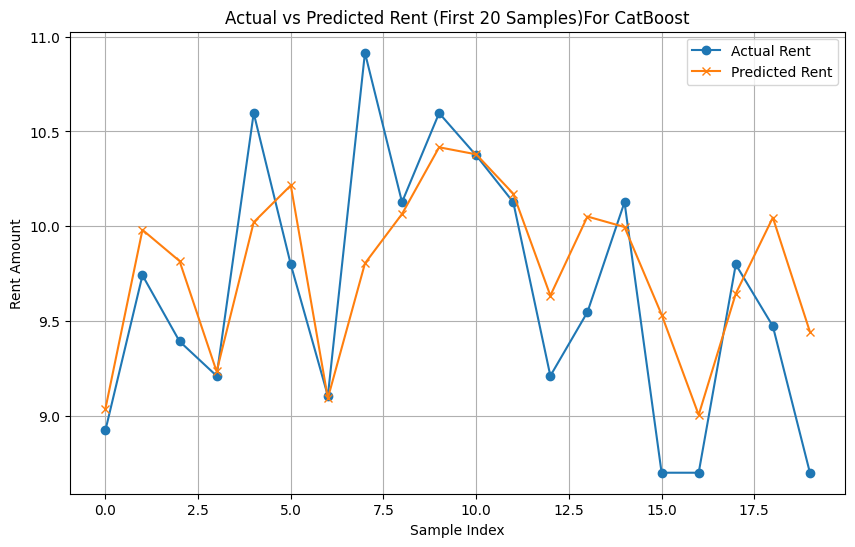

 93%|█████████▎| 14/15 [00:32<00:00,  1.10it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000477 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 718
[LightGBM] [Info] Number of data points in the train set: 3796, number of used features: 14
[LightGBM] [Info] Start training from score 9.864251


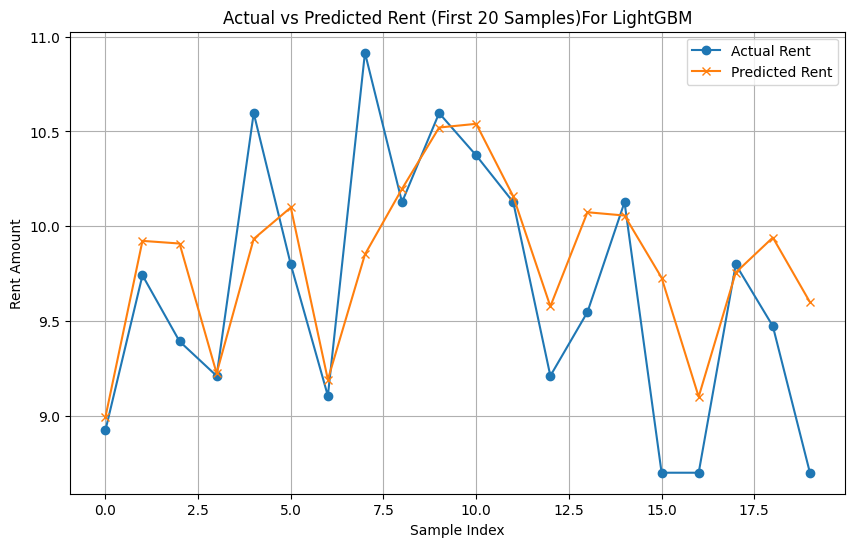

100%|██████████| 15/15 [00:33<00:00,  2.21s/it]


In [81]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [82]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [83]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [84]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [85]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Ridge,0.300230,0.309271,0.166074,0.176629,0.407521,0.420272,0.809907,0.799216
Linear Regression,0.299917,0.309445,0.165762,0.177170,0.407139,0.420916,0.810263,0.798600
SVM,0.299107,0.309106,0.166630,0.178390,0.408204,0.422363,0.809269,0.797213
KNN,0.259482,0.332944,0.124332,0.202993,0.352608,0.450548,0.857685,0.769246
ExtraTrees,0.000305,0.343812,0.000024,0.222832,0.004925,0.472051,0.999972,0.746694
Weighted Voting,0.129592,0.410155,0.031294,0.348049,0.176901,0.589957,0.964180,0.735782
Voting,0.116901,0.410155,0.025756,0.348049,0.160487,0.589957,0.970519,0.718888
Simple Voting,0.116901,0.410155,0.025756,0.348049,0.160487,0.589957,0.970519,0.718888
GradientBoosting,0.198271,0.402697,0.072513,0.319255,0.269282,0.565027,0.916999,0.637084
CatBoost,0.197323,0.394794,0.069129,0.320194,0.262923,0.565857,0.920873,0.636017


<Axes: >

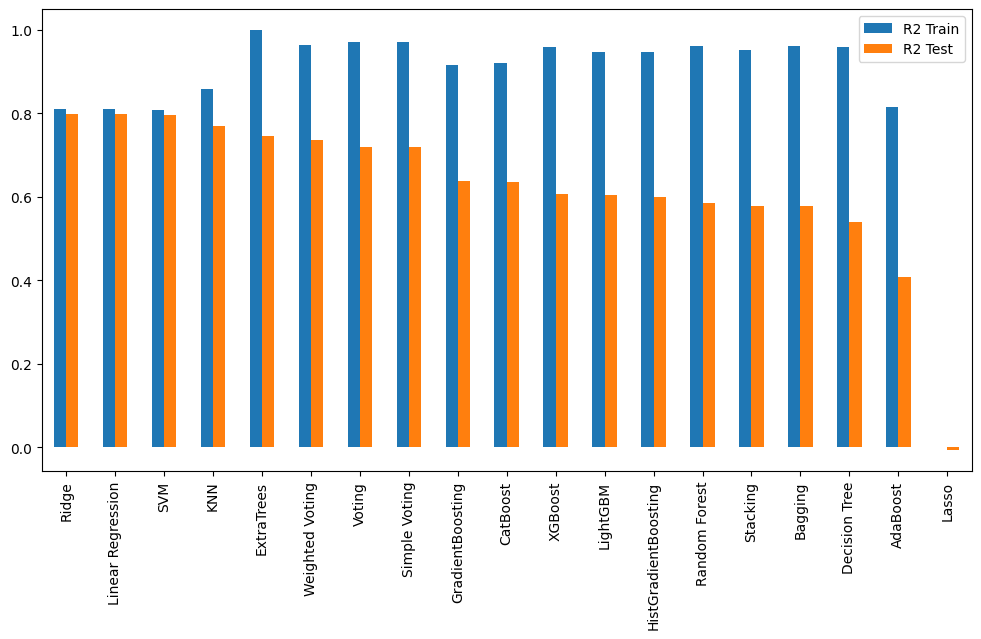

In [86]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

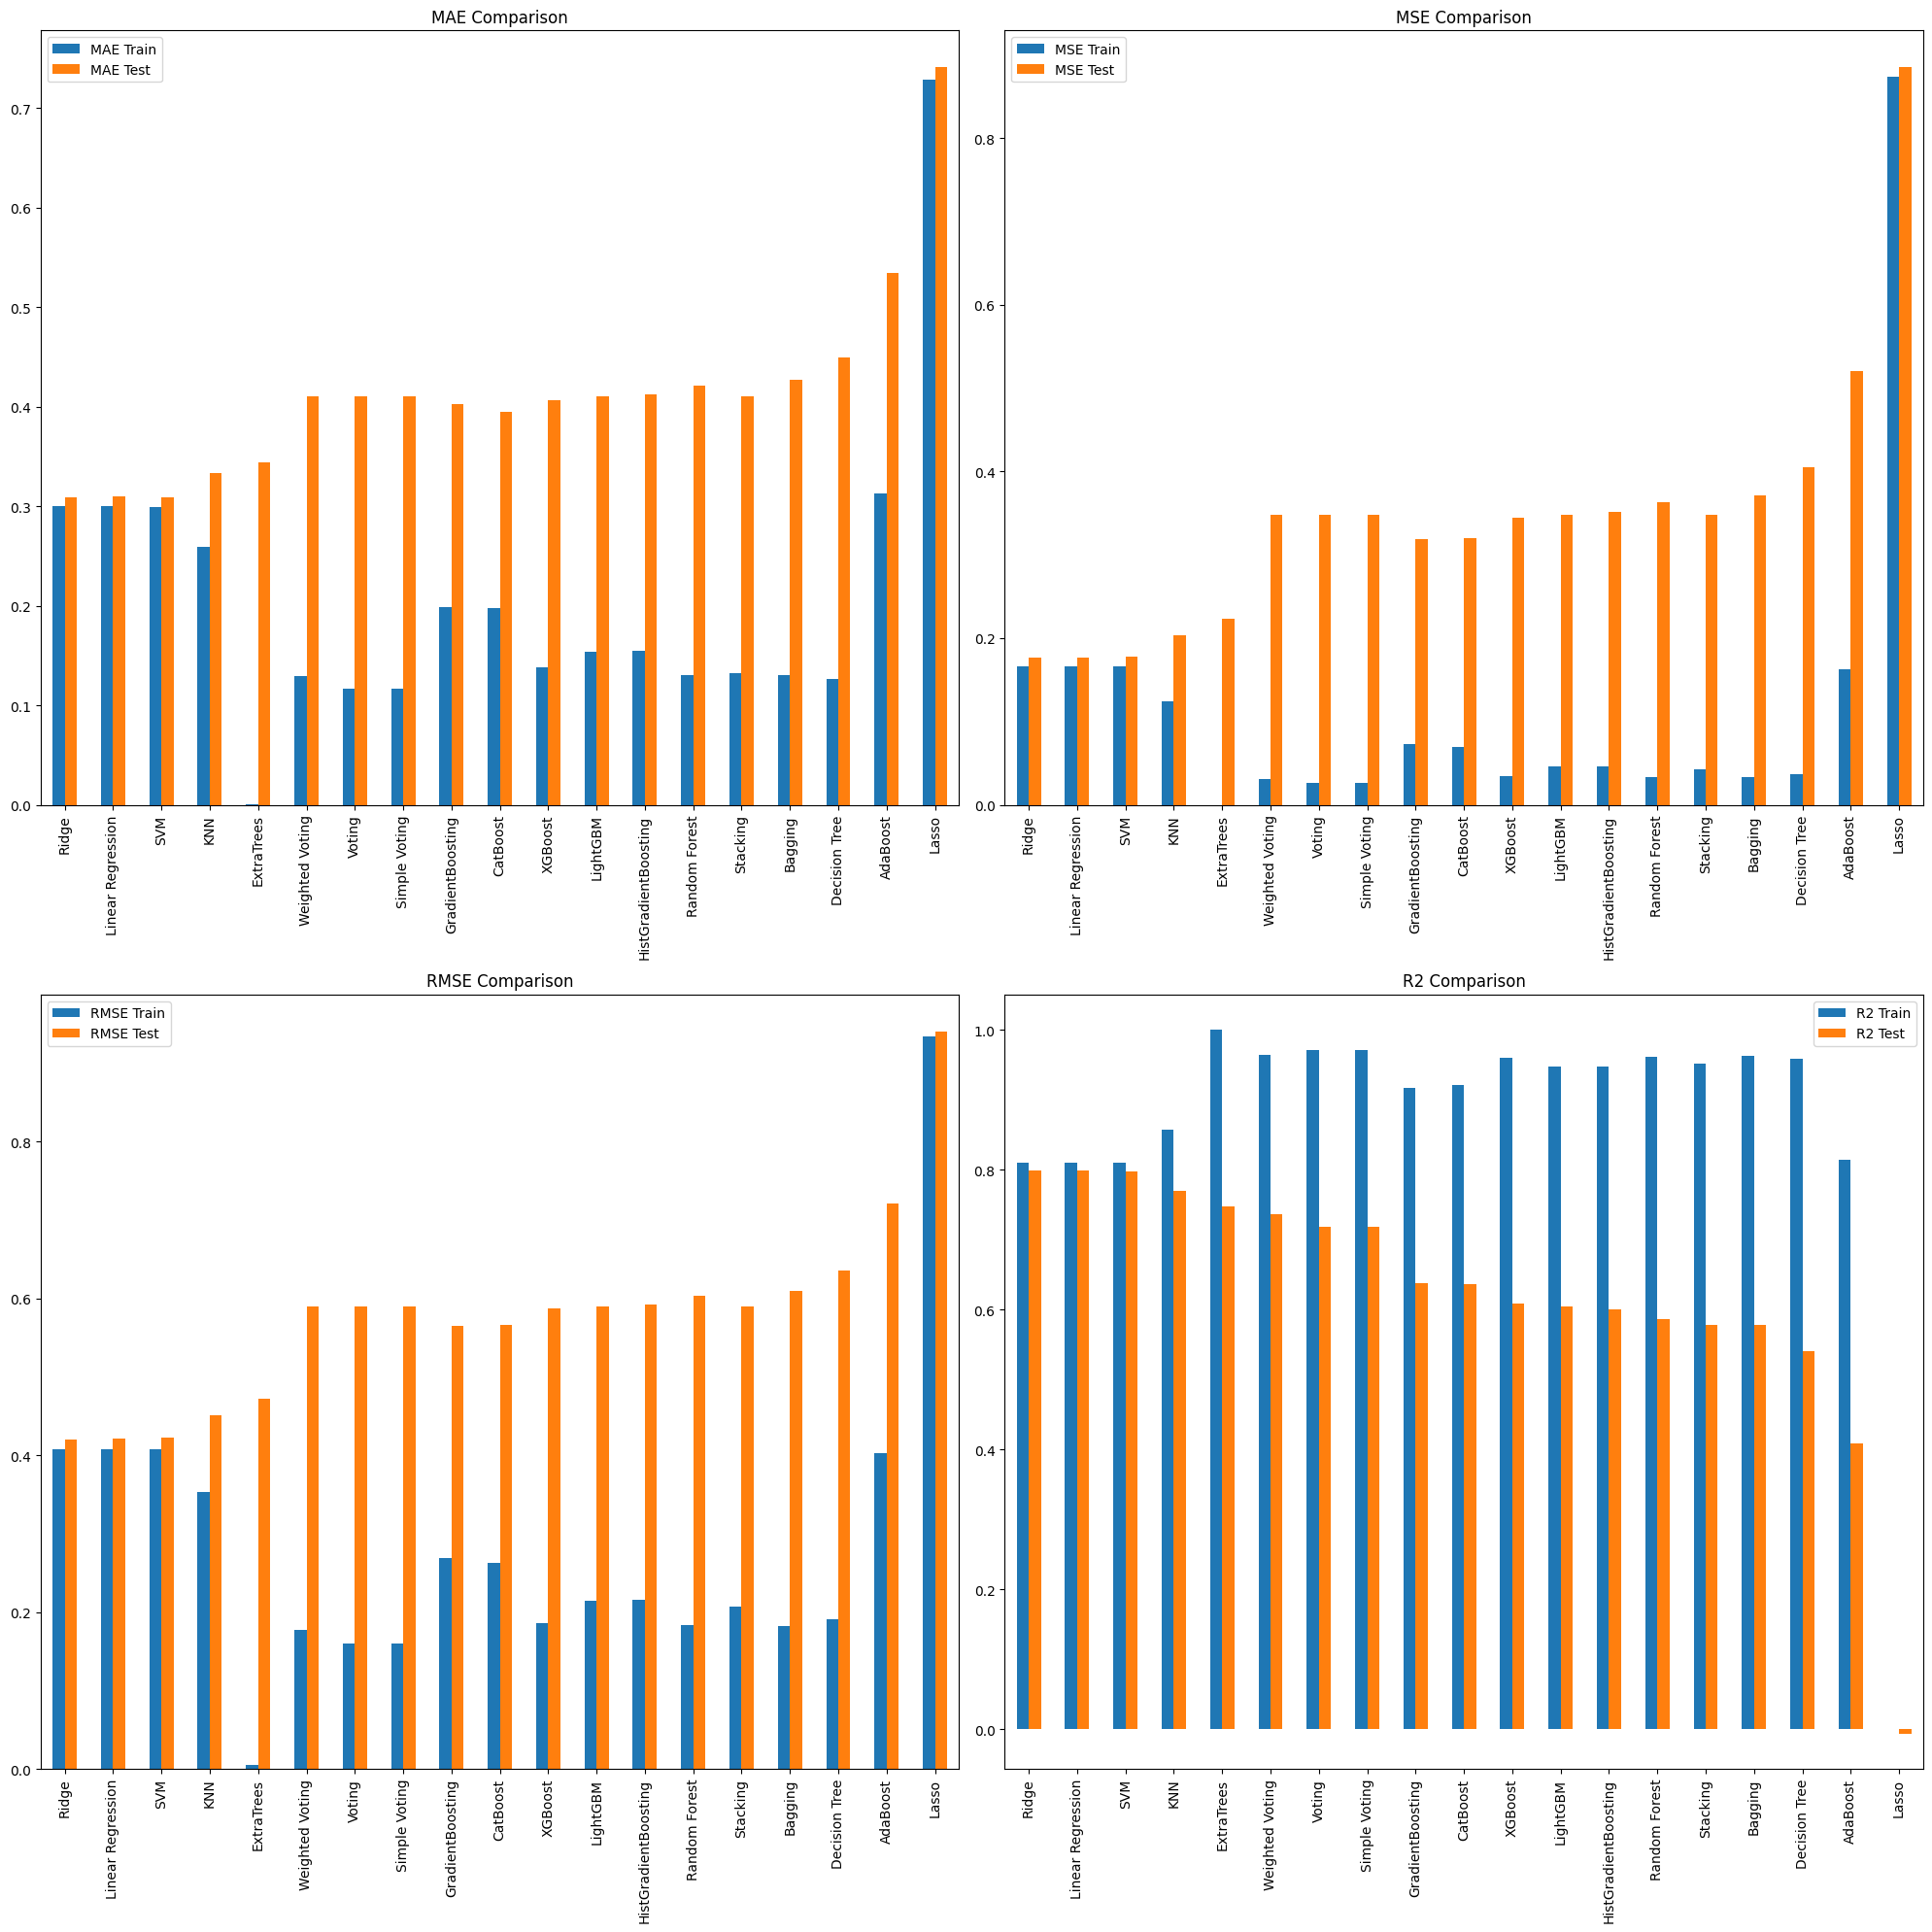

In [87]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()